In [18]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## EN4554 Assignment 2 - Convolutional Neural Networks

##### **Name:** Jayarathne H.A.C.N.
##### **Index number:** 220252U
##### **GitHub profile:** (https://github.com/Nithira17/EN4554-Assignment_2-CNNs)


### 0. Setup

In [32]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

In [33]:
seed = 0
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


In [ ]:
# load the CIFAR-10 training set
train_data = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
X = torch.tensor(train_data.data).permute(0, 3, 1, 2).float() / 255   # shape (50000, 3, 32, 32)
y = torch.tensor(train_data.targets)

# split: 45k train, 5k validation
perm = torch.randperm(50000)
X_train, y_train = X[perm[:45000]], y[perm[:45000]]
X_val, y_val = X[perm[45000:]], y[perm[45000:]]

# normalise each channel with the training set mean and std
mean = X_train.mean(dim=(0, 2, 3), keepdim=True)
std = X_train.std(dim=(0, 2, 3), keepdim=True)
X_train = (X_train - mean) / std
X_val = (X_val - mean) / std

print('train:', X_train.shape, '| val:', X_val.shape)
print('channel means:', mean.flatten())
print('channel stds :', std.flatten())

train: torch.Size([45000, 3, 32, 32]) | val: torch.Size([5000, 3, 32, 32])
channel means: tensor([0.4912, 0.4820, 0.4464])
channel stds : tensor([0.2472, 0.2436, 0.2617])


### Task 1: Backpropagation

#### (a) Linear, ReLU and softmax cross-entropy with explicit forward/backward

In [35]:
class Linear:
    def __init__(self, n_in, n_out):
        self.W = torch.randn(n_in, n_out) * np.sqrt(2 / n_in)
        self.b = torch.zeros(n_out)

    def forward(self, x):
        self.x = x 
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(0)
        return dout @ self.W.T


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        shifted = logits - logits.max(dim=1, keepdim=True).values
        exp = shifted.exp()
        self.probs = exp / exp.sum(dim=1, keepdim=True)
        self.y = y
        return -torch.log(self.probs[torch.arange(len(y)), y]).mean()

    def backward(self):
        N = len(self.y)
        d = self.probs.clone()
        d[torch.arange(N), self.y] -= 1
        return d / N


class MLP:
    def __init__(self, sizes, act=ReLU):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1]))
            if i < len(sizes) - 2:
                self.layers.append(act())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        d = self.loss_fn.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)

#### (b) Gradient check

I am using a small MLP (10-8-5-3) in float64 and compare my gradients with
1. **autograd**
2. **centred finite differences**: $\frac{L(\theta+\epsilon) - L(\theta-\epsilon)}{2\epsilon}$ with $\epsilon = 10^{-6}$.

The relative error is $\frac{\|a-b\|}{\|a\|+\|b\|}$.

In [ ]:
torch.manual_seed(0)
net = MLP([10, 8, 5, 3])
linears = [l for l in net.layers if isinstance(l, Linear)]
for l in linears:
    l.W = l.W.double()
    l.b = l.b.double()

x = torch.randn(6, 10).double()
y_small = torch.randint(0, 3, (6,))

# 1) our gradients
net.loss(x, y_small)
net.backward()

# 2) autograd gradients
Ws = [l.W.clone().requires_grad_() for l in linears]
bs = [l.b.clone().requires_grad_() for l in linears]
h = x
for i in range(len(Ws)):
    h = h @ Ws[i] + bs[i]
    if i < len(Ws) - 1:
        h = torch.relu(h)
F.cross_entropy(h, y_small).backward()

# 3) finite differences
def numerical_grad(param, eps=1e-6):
    grad = torch.zeros_like(param)
    for idx in np.ndindex(*param.shape):
        old = param[idx].item()
        param[idx] = old + eps
        loss_plus = net.loss(x, y_small).item()
        param[idx] = old - eps
        loss_minus = net.loss(x, y_small).item()
        param[idx] = old
        grad[idx] = (loss_plus - loss_minus) / (2 * eps)
    return grad

def rel_error(a, b):
    return ((a - b).norm() / (a.norm() + b.norm())).item()

print('param | err vs autograd | err vs finite diff | allclose(autograd) | allclose(finite diff)')
for i, layer in enumerate(linears):
    for name, p, mine, auto in [('W', layer.W, layer.dW, Ws[i].grad), ('b', layer.b, layer.db, bs[i].grad)]:
        num = numerical_grad(p)
        print(f'{name}{i + 1}    | {rel_error(mine, auto):.2e}         | {rel_error(mine, num):.2e}           | '
              f'{torch.allclose(mine, auto)}               | {torch.allclose(mine, num, atol=1e-6)}')

param | err vs autograd | err vs finite diff | allclose(autograd) | allclose(finite diff)
W1    | 7.04e-17         | 4.95e-10           | True               | True
b1    | 8.97e-17         | 6.20e-10           | True               | True
W2    | 9.69e-17         | 3.20e-10           | True               | True
b2    | 1.20e-16         | 6.29e-10           | True               | True
W3    | 4.86e-17         | 2.40e-10           | True               | True
b3    | 1.74e-16         | 4.28e-10           | True               | True


The relative error against autograd is around $10^{-16}$, which is the machine precision of float64, so my backward pass gives the same numbers as autograd. The error against finite differences is larger (around $10^{-9}$ to $10^{-10}$) because finite differences are only an approximation (truncation error of order $\epsilon^2$ plus rounding error). `torch.allclose` is `True` for every weight and bias. So my forward/backward implementation of Linear, ReLU and softmax cross-entropy is correct.

#### (c) Train the MLP with SGD on flattened CIFAR-10

Network: 3072 → 256 → 128 → 10 with ReLU. 

In [37]:
def get_batches(X, y, batch_size):
    # shuffled mini-batches
    perm = torch.randperm(len(X))
    for i in range(0, len(X), batch_size):
        idx = perm[i:i + batch_size]
        yield X[idx], y[idx]

Xtr_flat = X_train.reshape(len(X_train), -1)
Xva_flat = X_val.reshape(len(X_val), -1)

torch.manual_seed(0)
net = MLP([3072, 256, 128, 10])
lr = 0.01
epochs = 20

train_losses, val_losses, val_accs = [], [], []
for epoch in range(epochs):
    total = 0
    for xb, yb in get_batches(Xtr_flat, y_train, 128):
        loss = net.loss(xb, yb)
        net.backward()
        for layer in net.layers:                 # SGD step
            if isinstance(layer, Linear):
                layer.W -= lr * layer.dW
                layer.b -= lr * layer.db
        total += loss.item() * len(xb)
    train_losses.append(total / len(Xtr_flat))
    val_losses.append(net.loss(Xva_flat, y_val).item())
    val_accs.append((net.forward(Xva_flat).argmax(1) == y_val).float().mean().item())
    print(f'epoch {epoch + 1:2d} | train loss {train_losses[-1]:.4f} | val loss {val_losses[-1]:.4f} | val acc {val_accs[-1]:.4f}')

epoch  1 | train loss 1.8317 | val loss 1.7267 | val acc 0.3908
epoch  2 | train loss 1.5871 | val loss 1.6454 | val acc 0.4228
epoch  3 | train loss 1.4880 | val loss 1.6113 | val acc 0.4336
epoch  4 | train loss 1.4175 | val loss 1.5665 | val acc 0.4552
epoch  5 | train loss 1.3595 | val loss 1.5455 | val acc 0.4656
epoch  6 | train loss 1.3111 | val loss 1.5236 | val acc 0.4780
epoch  7 | train loss 1.2681 | val loss 1.5128 | val acc 0.4818
epoch  8 | train loss 1.2295 | val loss 1.5184 | val acc 0.4784
epoch  9 | train loss 1.1932 | val loss 1.5212 | val acc 0.4772
epoch 10 | train loss 1.1597 | val loss 1.4973 | val acc 0.4878
epoch 11 | train loss 1.1277 | val loss 1.5207 | val acc 0.4842
epoch 12 | train loss 1.0972 | val loss 1.4949 | val acc 0.4944
epoch 13 | train loss 1.0666 | val loss 1.4858 | val acc 0.4974
epoch 14 | train loss 1.0370 | val loss 1.5051 | val acc 0.4922
epoch 15 | train loss 1.0113 | val loss 1.5051 | val acc 0.4966
epoch 16 | train loss 0.9846 | val loss 

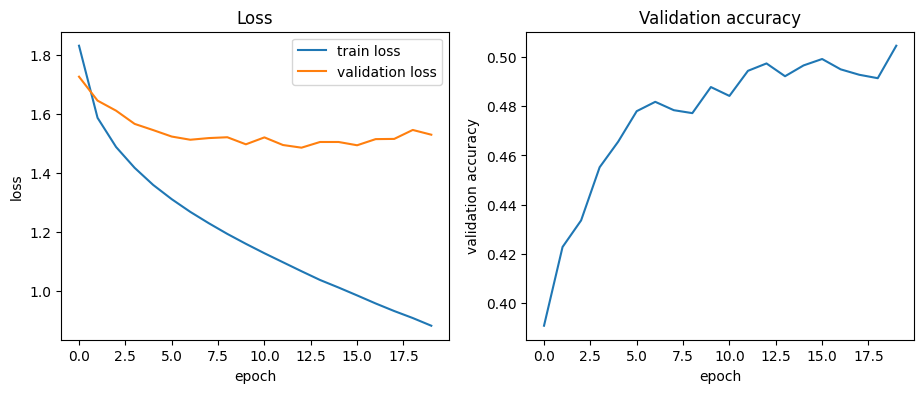

Final validation accuracy: 0.5045999884605408


In [38]:
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='train loss')
plt.plot(val_losses, label='validation loss')
plt.xlabel('epoch'); plt.ylabel('loss'); plt.title('Loss'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(val_accs)
plt.xlabel('epoch'); plt.ylabel('validation accuracy'); plt.title('Validation accuracy')
plt.show()
print('Final validation accuracy:', val_accs[-1])

The training loss goes down steadily, so the manual backpropagation and SGD work. The final validation accuracy is about **50.4%**. The validation loss reaches its minimum at around epoch **13** and then starts to rise, while the training loss keeps falling. This means the MLP starts to **overfit**: it memorises the training images. An MLP on flattened pixels ignores the 2D structure of the image and needs a separate weight for every pixel, so it generalises poorly.

#### (d) Per-layer gradient norms of a 10-layer MLP: sigmoid vs ReLU

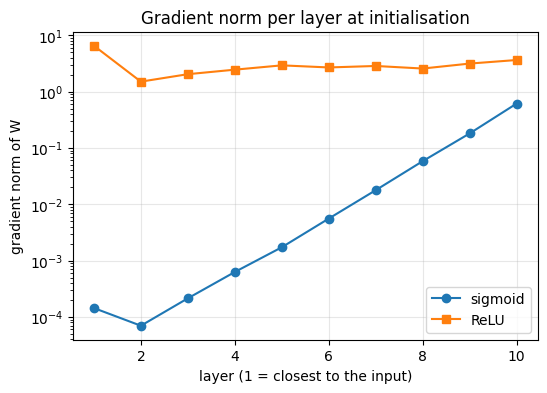

sigmoid layer 1 / layer 10 gradient ratio: 0.00023447254273657492
ReLU layer 1 / layer 10 gradient ratio: 1.792911587300411


In [39]:
class Sigmoid:
    def forward(self, x):
        self.out = torch.sigmoid(x)
        return self.out

    def backward(self, dout):
        return dout * self.out * (1 - self.out)

xb, yb = Xtr_flat[:128], y_train[:128]
sizes = [3072] + [100] * 9 + [10]

norms = {}
for name, act in [('sigmoid', Sigmoid), ('ReLU', ReLU)]:
    torch.manual_seed(0)
    deep_net = MLP(sizes, act=act)
    deep_net.loss(xb, yb)
    deep_net.backward()
    norms[name] = [l.dW.norm().item() for l in deep_net.layers if isinstance(l, Linear)]

layers = range(1, 11)
plt.figure(figsize=(6, 4))
plt.semilogy(layers, norms['sigmoid'], 'o-', label='sigmoid')
plt.semilogy(layers, norms['ReLU'], 's-', label='ReLU')
plt.xlabel('layer (1 = closest to the input)')
plt.ylabel('gradient norm of W')
plt.title('Gradient norm per layer at initialisation')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

for name in norms:
    print(name, 'layer 1 / layer 10 gradient ratio:', norms[name][0] / norms[name][-1])

With **sigmoid**, the gradient norm becomes smaller and smaller as we go back towards the input. This is the **vanishing gradient** problem. The derivative of the sigmoid is at most 0.25, and in backpropagation the gradient is multiplied by this value at every layer, so after 10 layers it is tiny. The early layers hardly learn. With **ReLU**, the derivative is 1 for positive inputs, so the gradient does not shrink layer by layer and the norms stay about the same in all layers. So ReLU makes deep networks much easier to train.

### Task 2: Optimizers

#### (a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

In [40]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if len(state) == 0:
                    state['v'] = torch.zeros_like(p)
                v = state['v']
                v.mul_(group['momentum']).add_(p.grad)     # v = mu*v + g
                p.add_(v, alpha=-group['lr'])               # p = p - lr*v


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if len(state) == 0:
                    state['t'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)
                state['t'] += 1
                t = state['t']
                g = p.grad
                state['m'].mul_(b1).add_(g, alpha=1 - b1)              # first moment
                state['v'].mul_(b2).addcmul_(g, g, value=1 - b2)       # second moment
                m_hat = state['m'] / (1 - b1 ** t)                     # bias correction
                v_hat = state['v'] / (1 - b2 ** t)
                p.sub_(group['lr'] * m_hat / (v_hat.sqrt() + group['eps']))

I train two identical copies of a small network (float64) on the same 50 mini-batches, one with my optimizer and one with the PyTorch optimizer, and then compare all the parameters.

In [41]:
import copy

def compare(my_opt, torch_opt):
    torch.manual_seed(0)
    model1 = nn.Sequential(nn.Flatten(), nn.Linear(3072, 32), nn.ReLU(), nn.Linear(32, 10)).double()
    model2 = copy.deepcopy(model1)
    opt1 = my_opt(model1.parameters())
    opt2 = torch_opt(model2.parameters())
    for step in range(50):
        xb = X_train[step * 64:(step + 1) * 64].double()
        yb = y_train[step * 64:(step + 1) * 64]
        for model, opt in [(model1, opt1), (model2, opt2)]:
            opt.zero_grad()
            F.cross_entropy(model(xb), yb).backward()
            opt.step()
    same = all(torch.allclose(a, b) for a, b in zip(model1.parameters(), model2.parameters()))
    diff = max((a - b).abs().max().item() for a, b in zip(model1.parameters(), model2.parameters()))
    return same, diff

tests = [
    ('SGD (no momentum)', lambda p: MySGD(p, lr=0.01),                 lambda p: torch.optim.SGD(p, lr=0.01)),
    ('SGD with momentum', lambda p: MySGD(p, lr=0.01, momentum=0.9),   lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9)),
    ('Adam',              lambda p: MyAdam(p, lr=1e-3),                lambda p: torch.optim.Adam(p, lr=1e-3)),
]
for name, mine, theirs in tests:
    same, diff = compare(mine, theirs)
    print(f'{name:20s} | allclose: {same} | max difference: {diff:.2e}')

SGD (no momentum)    | allclose: True | max difference: 0.00e+00
SGD with momentum    | allclose: True | max difference: 0.00e+00
Adam                 | allclose: True | max difference: 5.55e-17


For all three cases `torch.allclose` is `True` and the largest difference in any parameter after 50 steps is around $10^{-16}$ or smaller. So my SGD, SGD with momentum and Adam do the same thing as `torch.optim.SGD` and `torch.optim.Adam`.

#### (b) Trajectories on $f(x,y) = \frac{1}{2}(x^2 + 50y^2)$

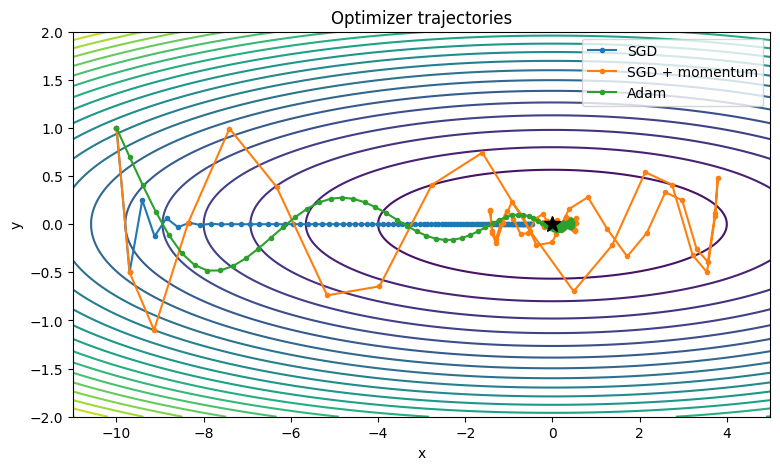

SGD             final point = (-0.4755, 0.0000),  f = 1.13e-01
SGD + momentum  final point = (0.0248, -0.0011),  f = 3.38e-04
Adam            final point = (-0.0513, -0.0016),  f = 1.38e-03


In [42]:
def f(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def run(opt_class, steps=100, **kwargs):
    p = torch.tensor([-10.0, 1.0], requires_grad=True)
    opt = opt_class([p], **kwargs)
    path = [p.detach().clone().numpy()]
    for _ in range(steps):
        opt.zero_grad()
        f(p).backward()
        opt.step()
        path.append(p.detach().clone().numpy())
    return np.array(path)

paths = {
    'SGD': run(MySGD, lr=0.03),
    'SGD + momentum': run(MySGD, lr=0.03, momentum=0.9),
    'Adam': run(MyAdam, lr=0.3),
}

# contour plot of f
xs, ys = np.meshgrid(np.linspace(-11, 5, 300), np.linspace(-2, 2, 300))
Z = 0.5 * (xs ** 2 + 50 * ys ** 2)
plt.figure(figsize=(9, 5))
plt.contour(xs, ys, Z, levels=20)
for name, path in paths.items():
    plt.plot(path[:, 0], path[:, 1], '.-', label=name)
plt.plot(0, 0, 'k*', markersize=12)
plt.xlabel('x'); plt.ylabel('y'); plt.title('Optimizer trajectories'); plt.legend()
plt.show()

for name, path in paths.items():
    print(f'{name:15s} final point = ({path[-1, 0]:.4f}, {path[-1, 1]:.4f}),  f = {f(torch.tensor(path[-1])).item():.2e}')

This function is a long narrow valley: the curvature is 50 along $y$ but only 1 along $x$. All optimizers in my implementations start at $(-10, 1)$ and take 100 steps. Learning rates: SGD 0.03, SGD with momentum 0.03 ($\mu = 0.9$), Adam 0.3.

* **SGD:** With 0.03, $y$ goes to zero quickly, but in the flat $x$ direction the step is tiny, so SGD moves slowly and after 100 steps it is still not at the minimum. The steep direction limits the learning rate and the flat direction is slow.
* **SGD with momentum:** in the $x$ direction all the gradients point the same way, so the velocity builds up and the effective step becomes about $10\times$ larger. It reaches the minimum much faster than SGD, but it overshoots and oscillates around it before settling.
* **Adam:** it divides each coordinate by the running average of its own gradient size, so $x$ and $y$ get steps of similar size even though their gradients are very different. The path goes more directly towards the minimum. Because the learning rate is constant, it still oscillates a little around the minimum.

#### (c) Learning-rate sensitivity on a small CNN

Small CNN: conv(32)-ReLU-pool → conv(64)-ReLU-pool → FC(128)-ReLU → FC(10).

I train it with my own optimizers at three learning rates each (10 epochs, batch size 128). The same initial weights (same seed) are used in every run.

In [43]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


def accuracy(model, X, y):
    model.eval()
    correct = 0
    with torch.no_grad():
        for i in range(0, len(X), 1000):
            out = model(X[i:i + 1000].to(device))
            correct += (out.argmax(1).cpu() == y[i:i + 1000]).sum().item()
    return correct / len(X)


def train(model, optimizer, epochs, X, y, Xv, yv, bs=128):
    train_losses, val_accs = [], []
    for epoch in range(epochs):
        model.train()
        total = 0
        for xb, yb in get_batches(X, y, bs):
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        train_losses.append(total / len(X))
        val_accs.append(accuracy(model, Xv, yv))
    return train_losses, val_accs

In [44]:
EPOCHS_2C = 10

settings = {
    'SGD':          (lambda p, lr: MySGD(p, lr=lr),               [0.001, 0.01, 0.1]),
    'SGD momentum': (lambda p, lr: MySGD(p, lr=lr, momentum=0.9), [0.001, 0.01, 0.1]),
    'Adam':         (lambda p, lr: MyAdam(p, lr=lr),              [0.0001, 0.001, 0.01]),
}

results_2c = {}
for opt_name, (make_opt, lrs) in settings.items():
    for lr in lrs:
        torch.manual_seed(0)
        model = SmallCNN().to(device)
        optimizer = make_opt(model.parameters(), lr)
        results_2c[(opt_name, lr)] = train(model, optimizer, EPOCHS_2C, X_train, y_train, X_val, y_val)
        print(f'{opt_name:13s} lr={lr:<7} | final train loss {results_2c[(opt_name, lr)][0][-1]:.4f} '
              f'| final val acc {results_2c[(opt_name, lr)][1][-1]:.4f}')

SGD           lr=0.001   | final train loss 1.8667 | final val acc 0.3430
SGD           lr=0.01    | final train loss 1.0862 | final val acc 0.5980
SGD           lr=0.1     | final train loss 0.2948 | final val acc 0.6712
SGD momentum  lr=0.001   | final train loss 1.0739 | final val acc 0.6042
SGD momentum  lr=0.01    | final train loss 0.2535 | final val acc 0.7134
SGD momentum  lr=0.1     | final train loss 0.8010 | final val acc 0.5926
Adam          lr=0.0001  | final train loss 0.9800 | final val acc 0.6294
Adam          lr=0.001   | final train loss 0.3291 | final val acc 0.7072
Adam          lr=0.01    | final train loss 2.3035 | final val acc 0.1004


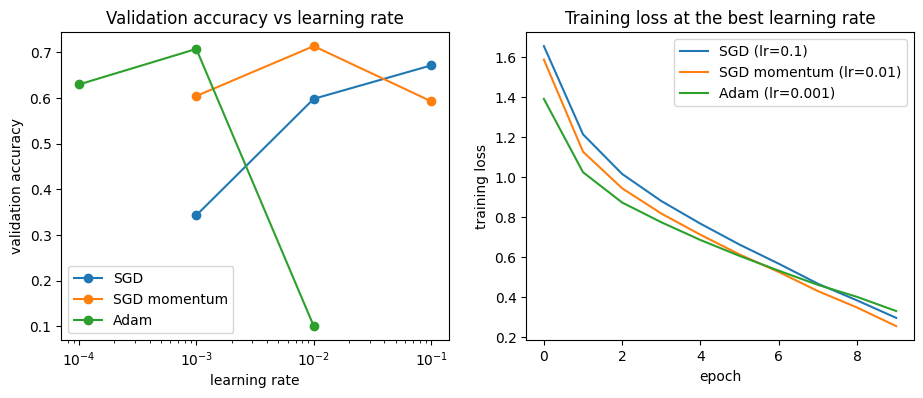

In [45]:
plt.figure(figsize=(11, 4))

# left: validation accuracy vs learning rate
plt.subplot(1, 2, 1)
best_lr = {}
for opt_name, (make_opt, lrs) in settings.items():
    accs = [results_2c[(opt_name, lr)][1][-1] for lr in lrs]
    best_lr[opt_name] = lrs[int(np.argmax(accs))]
    plt.semilogx(lrs, accs, 'o-', label=opt_name)
plt.xlabel('learning rate'); plt.ylabel('validation accuracy')
plt.title('Validation accuracy vs learning rate'); plt.legend()

# right: training loss at the best learning rate of each optimizer
plt.subplot(1, 2, 2)
for opt_name in settings:
    plt.plot(results_2c[(opt_name, best_lr[opt_name])][0], label=f'{opt_name} (lr={best_lr[opt_name]})')
plt.xlabel('epoch'); plt.ylabel('training loss')
plt.title('Training loss at the best learning rate'); plt.legend()
plt.show()

Each optimizer only works well in a narrow range of learning rates.
* **SGD:** with the smallest learning rate (0.001) the network learns very slowly, and the loss hardly moves in 10 epochs. The best learning rate for SGD is the largest one (**0.1**), with a validation accuracy of **67.12%**.
* **SGD with momentum:** it behaves like SGD with a learning rate about $1/(1-\mu) = 10$ times larger, so its best learning rate is smaller than for plain SGD (**0.01**, accuracy **71.34%**). At the largest learning rate it can become unstable.
* **Adam:** its best learning rate is **0.001** (accuracy **70.72%**), and its training loss goes down fastest. When the learning rate is too large (0.01) the accuracy becomes **10%**, because every weight moves by about the learning rate in each step.

So the learning rate has to be tuned separately for each optimizer, and the best accuracies of the three optimizers are quite similar when each is used at its own best learning rate. Adam is the least sensitive at small learning rates but fails when the rate is too large. SGD needs a large learning rate and momentum acts like a larger effective learning rate.

### Task 3: Regularization and residual connections

#### (a) Regularization study on 5k training images

I use a small CNN **with batch norm** and train on only the first 5000 training images. The validation set is the same 5k validation images. The settings are SGD with momentum 0.9, learning rate 0.01, batch size 128, 40 epochs. In each experiment only one thing is changed from the baseline.

| experiment | added components |
|---|---|
| baseline | - |
| weight decay | L2 weight decay $5\times10^{-4}$ |
| dropout | dropout $p=0.5$ before the FC layers |
| flip+crop | random horizontal flip and random crop (pad 4) |
| cutout | a random 16×16 square set to zero |
| mixup | mixup with $\alpha = 1$ |
| all combined | all of the above |


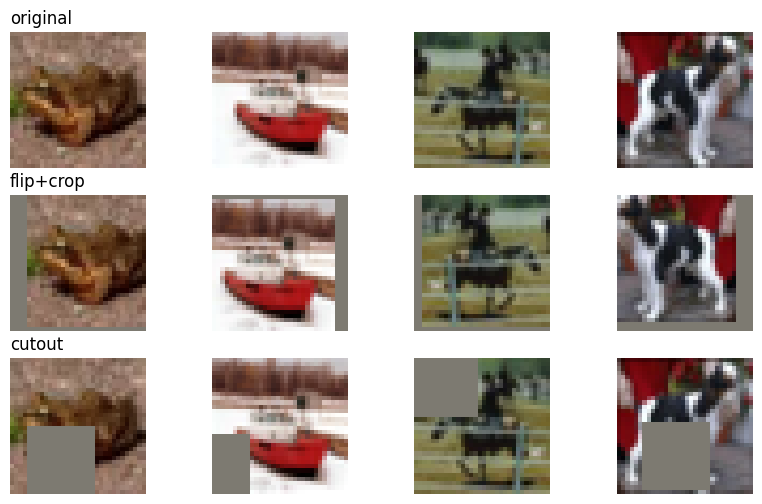

In [47]:
def flip_crop(x, pad=4):
    # random horizontal flip + random 32x32 crop from the image padded by 4 pixels
    xp = F.pad(x, (pad, pad, pad, pad))
    out = torch.zeros_like(x)
    for i in range(len(x)):
        img = xp[i]
        if np.random.rand() < 0.5:
            img = img.flip(2)
        dy, dx = np.random.randint(0, 2 * pad + 1, 2)
        out[i] = img[:, dy:dy + 32, dx:dx + 32]
    return out


def cutout(x, size=16):
    # set a random size x size square to 0
    x = x.clone()
    for i in range(len(x)):
        cy, cx = np.random.randint(0, 32, 2)
        y1, y2 = max(0, cy - size // 2), min(32, cy + size // 2)
        x1, x2 = max(0, cx - size // 2), min(32, cx + size // 2)
        x[i, :, y1:y2, x1:x2] = 0
    return x


def mixup(x, y, alpha=1.0):
    # mix every image with another random image of the batch
    lam = float(np.random.beta(alpha, alpha))
    idx = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam


sample = X_train[:4]
plt.figure(figsize=(10, 6))
for row, (title, func) in enumerate([('original', lambda a: a), ('flip+crop', flip_crop), ('cutout', cutout)]):
    imgs = func(sample)
    for j in range(4):
        plt.subplot(3, 4, row * 4 + j + 1)
        img = (imgs[j] * std[0] + mean[0]).permute(1, 2, 0).clamp(0, 1)   # undo the normalisation
        plt.imshow(img); plt.axis('off')
        if j == 0:
            plt.title(title, loc='left')
plt.show()

In [48]:
class SmallCNN_BN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout), nn.Linear(64 * 8 * 8, 128), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


def train_reg(model, optimizer, epochs, X, y, Xv, yv, augment=None, use_mixup=False, scheduler=None, bs=128):
    hist = {'train_loss': [], 'train_acc': [], 'val_acc': []}
    for epoch in range(epochs):
        model.train()
        total = 0
        for xb, yb in get_batches(X, y, bs):
            xb, yb = xb.to(device), yb.to(device)
            if augment is not None:
                xb = augment(xb)
            if use_mixup:
                xb, y_a, y_b, lam = mixup(xb, yb)
                out = model(xb)
                loss = lam * F.cross_entropy(out, y_a) + (1 - lam) * F.cross_entropy(out, y_b)
            else:
                loss = F.cross_entropy(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        if scheduler is not None:
            scheduler.step()
        hist['train_loss'].append(total / len(X))
        hist['train_acc'].append(accuracy(model, X[:5000], y[:5000]))
        hist['val_acc'].append(accuracy(model, Xv, yv))
    return hist

In [49]:
EPOCHS_3A = 40
X_5k, y_5k = X_train[:5000], y_train[:5000]

configs = {
    'baseline':     dict(),
    'weight decay': dict(wd=5e-4),
    'dropout':      dict(dropout=0.5),
    'flip+crop':    dict(augment=flip_crop),
    'cutout':       dict(augment=cutout),
    'mixup':        dict(use_mixup=True),
    'all combined': dict(wd=5e-4, dropout=0.5, augment=lambda x: cutout(flip_crop(x)), use_mixup=True),
}

results_3a = {}
for name, cfg in configs.items():
    torch.manual_seed(0)
    model = SmallCNN_BN(dropout=cfg.get('dropout', 0.0)).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=cfg.get('wd', 0.0))
    results_3a[name] = train_reg(model, optimizer, EPOCHS_3A, X_5k, y_5k, X_val, y_val,
                                 augment=cfg.get('augment'), use_mixup=cfg.get('use_mixup', False))
    print(f'{name:13s} | train acc {results_3a[name]["train_acc"][-1]:.4f} | val acc {results_3a[name]["val_acc"][-1]:.4f}')

baseline      | train acc 1.0000 | val acc 0.6064
weight decay  | train acc 1.0000 | val acc 0.6010
dropout       | train acc 0.8304 | val acc 0.6096
flip+crop     | train acc 0.7846 | val acc 0.6582
cutout        | train acc 0.9862 | val acc 0.5818
mixup         | train acc 0.9850 | val acc 0.5716
all combined  | train acc 0.5404 | val acc 0.5146


              train acc  val acc  gap (train - val)
baseline         1.0000   0.6064             0.3936
weight decay     1.0000   0.6010             0.3990
dropout          0.8304   0.6096             0.2208
flip+crop        0.7846   0.6582             0.1264
cutout           0.9862   0.5818             0.4044
mixup            0.9850   0.5716             0.4134
all combined     0.5404   0.5146             0.0258


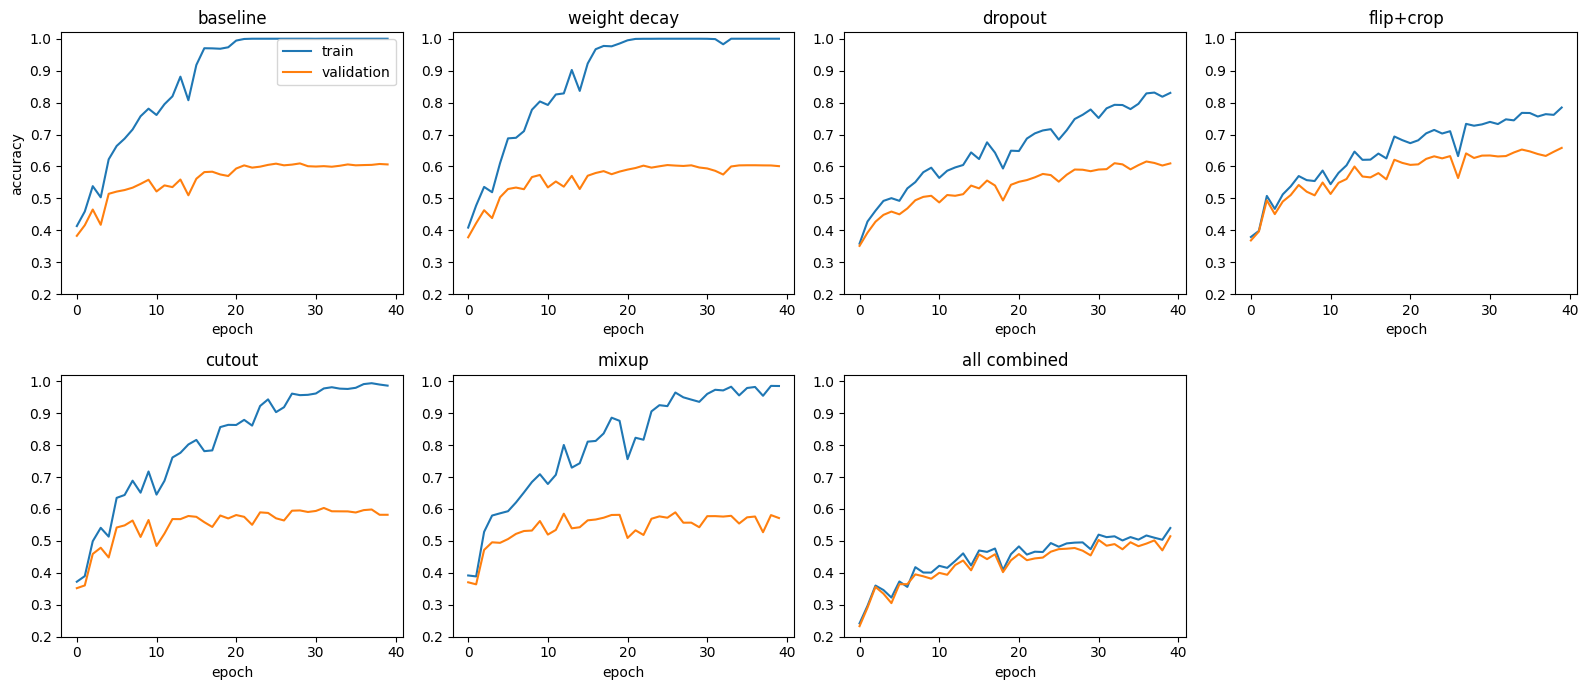

In [50]:
import pandas as pd

table = pd.DataFrame({
    'train acc': {n: h['train_acc'][-1] for n, h in results_3a.items()},
    'val acc':   {n: h['val_acc'][-1] for n, h in results_3a.items()},
})
table['gap (train - val)'] = table['train acc'] - table['val acc']
print(table.round(4))

plt.figure(figsize=(16, 7))
for i, (name, h) in enumerate(results_3a.items()):
    plt.subplot(2, 4, i + 1)
    plt.plot(h['train_acc'], label='train')
    plt.plot(h['val_acc'], label='validation')
    plt.title(name); plt.xlabel('epoch'); plt.ylim(0.2, 1.02)
    if i == 0:
        plt.ylabel('accuracy'); plt.legend()
plt.tight_layout()
plt.show()

* **Baseline:** with only 5k images the network reaches about **100%** training accuracy but only **60.64%** validation accuracy, so the gap is large (**39.36**). It overfits.
* **Weight decay** also behaves similar to baseline. 
* **dropout** reduce the gap a little. It helps only slightly here.
* **Flip+crop** is the best single method (**65.82%** validation accuracy). These transformations keep the label the same, so they act like having more training data.
* **Cutout** (**58.18%**) and **mixup** (**57.16%**) are less effective than flip+crop in this setting.
* **All combined** has the smallest gap (**2.58**), but its training accuracy is much lower (**54.04%**), so the model is now **underfitting** and the validation accuracy is not necessarily the best.

A smaller gap does not always mean a better model. Regularisation reduces overfitting but too much of it makes the model too weak, so the regularisers need to be balanced.

#### (b) Plain vs residual networks of depth $6n+2$

In [51]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.residual = residual
        self.stride = stride
        self.pad = (cout - cin) // 2

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            shortcut = x
            if self.stride == 2:
                shortcut = x[:, :, ::2, ::2]                              # subsample
                shortcut = F.pad(shortcut, (0, 0, 0, 0, self.pad, self.pad))   # zero-pad the channels
            out = out + shortcut
        return F.relu(out)


class CifarNet(nn.Module):
    def __init__(self, n, residual):
        super().__init__()
        self.conv = nn.Conv2d(3, 16, 3, 1, 1, bias=False)
        self.bn = nn.BatchNorm2d(16)
        blocks = []
        cin = 16
        for cout, stride in [(16, 1), (32, 2), (64, 2)]:
            for i in range(n):
                blocks.append(Block(cin, cout, stride if i == 0 else 1, residual))
                cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, 10)
        for m in self.modules():                       # Kaiming initialisation
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight)

    def forward(self, x):
        out = F.relu(self.bn(self.conv(x)))
        out = self.blocks(out)
        out = out.mean(dim=(2, 3))                     # global average pooling
        return self.fc(out)


for n in [1, 3, 9]:
    plain, res = CifarNet(n, False), CifarNet(n, True)
    print(f'depth {6 * n + 2:2d} | plain params {sum(p.numel() for p in plain.parameters()):,} '
          f'| residual params {sum(p.numel() for p in res.parameters()):,}')

depth  8 | plain params 75,290 | residual params 75,290
depth 20 | plain params 269,722 | residual params 269,722
depth 56 | plain params 853,018 | residual params 853,018


In [53]:
EPOCHS_3B = 25

results_3b = {}
for n in [1, 3, 9]:
    for residual in [False, True]:
        torch.manual_seed(0)
        model = CifarNet(n, residual).to(device)
        optimizer = torch.optim.SGD(model.parameters(), lr=0.02, momentum=0.9, weight_decay=1e-4)
        results_3b[(6 * n + 2, residual)] = train_reg(model, optimizer, EPOCHS_3B, X_train, y_train, X_val, y_val)
        h = results_3b[(6 * n + 2, residual)]
        print(f'depth {6 * n + 2:2d} {"residual" if residual else "plain   "} | final train loss {h["train_loss"][-1]:.4f} '
              f'| val acc {h["val_acc"][-1]:.4f}')

depth  8 plain    | final train loss 0.3556 | val acc 0.7300
depth  8 residual | final train loss 0.3554 | val acc 0.7242
depth 20 plain    | final train loss 0.1463 | val acc 0.7794
depth 20 residual | final train loss 0.0727 | val acc 0.7630
depth 56 plain    | final train loss 0.6649 | val acc 0.5742
depth 56 residual | final train loss 0.0409 | val acc 0.7620


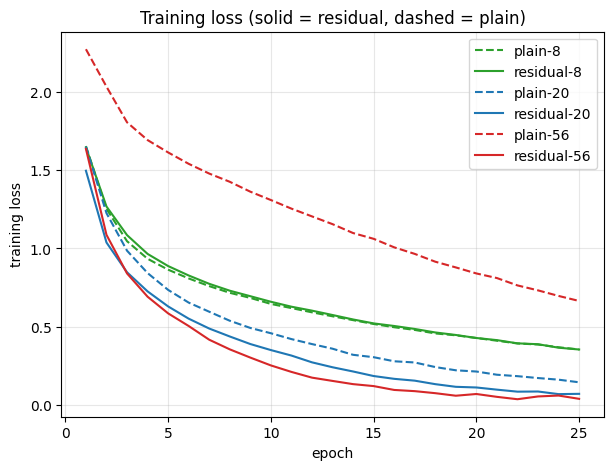

In [54]:
colors = {8: 'tab:green', 20: 'tab:blue', 56: 'tab:red'}
plt.figure(figsize=(7, 5))
for (depth, residual), h in results_3b.items():
    plt.plot(range(1, EPOCHS_3B + 1), h['train_loss'], color=colors[depth], linestyle='-' if residual else '--',
             label=f'{"residual" if residual else "plain"}-{depth}')
plt.xlabel('epoch'); plt.ylabel('training loss')
plt.title('Training loss (solid = residual, dashed = plain)')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

* **Plain networks:** going from depth 8 to depth 20 help, but depth 56 gives a **higher training loss** than depth 20. The deeper network is worse even on the *training* set, so this is not overfitting. It is an **optimisation (degradation) problem**.
* **Residual networks:** with exactly the same number of parameters, the deeper network is now **better**: the training loss goes down as the depth increases (**0.3554**, **0.0727**, **0.0409** for depths 8, 20, 56). 
* **At depth 8** the plain and residual networks behave almost the same, because a shallow network is already easy to train. The benefit of the shortcut gets bigger as the network gets deeper.

### Task 4: CNN

**Design.** I use the residual network from Task 3(b) with $n = 5$ (depth 32), because it has fewer than 500k parameters and the shortcuts make it easy to train. The training recipe is: SGD with momentum 0.9, learning rate 0.1 with cosine decay to zero, weight decay $5\times10^{-4}$, flip+crop augmentation, batch size 128, 20 epochs.

In [55]:
EPOCHS_4 = 20

def run_config(residual=True, augment=flip_crop, wd=5e-4, use_adam=False):
    torch.manual_seed(0)
    model = CifarNet(5, residual).to(device)
    if use_adam:
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=wd)
    else:
        optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_4)
    hist = train_reg(model, optimizer, EPOCHS_4, X_train, y_train, X_val, y_val, augment=augment, scheduler=scheduler)
    return model, hist

n_params = sum(p.numel() for p in CifarNet(5, True).parameters())
print('Number of parameters:', f'{n_params:,}', '(limit 500,000)')
assert n_params <= 500000

ablations = {
    'full model':        dict(),
    'no shortcut':       dict(residual=False),
    'no augmentation':   dict(augment=None),
    'no weight decay':   dict(wd=0.0),
    'Adam instead of SGD': dict(use_adam=True),
}

models_4, results_4 = {}, {}
for name, change in ablations.items():
    models_4[name], results_4[name] = run_config(**change)
    print(f'{name:20s} | train loss {results_4[name]["train_loss"][-1]:.4f} | val acc {results_4[name]["val_acc"][-1]:.4f}')

Number of parameters: 464,154 (limit 500,000)
full model           | train loss 0.3270 | val acc 0.8536
no shortcut          | train loss 0.4588 | val acc 0.8264
no augmentation      | train loss 0.0105 | val acc 0.8214
no weight decay      | train loss 0.3586 | val acc 0.8414
Adam instead of SGD  | train loss 0.2665 | val acc 0.8686


configuration          val acc   change vs full model
full model             0.8536    +0.0000
no shortcut            0.8264    -0.0272
no augmentation        0.8214    -0.0322
no weight decay        0.8414    -0.0122
Adam instead of SGD    0.8686    +0.0150


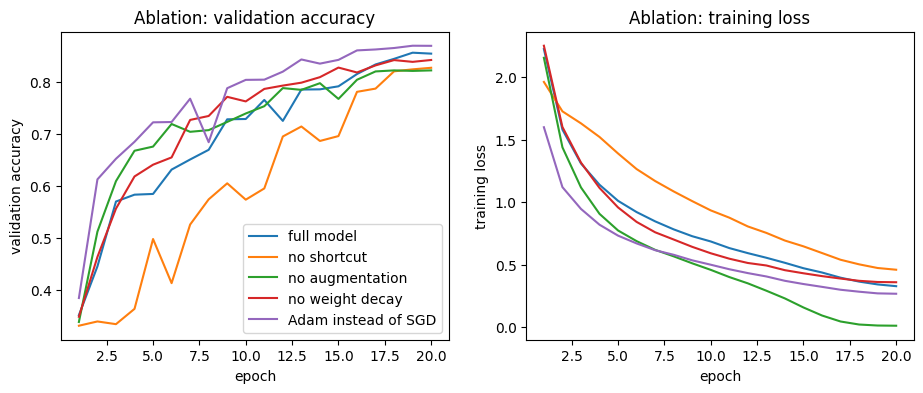

In [56]:
print(f'{"configuration":22s} val acc   change vs full model')
for name, h in results_4.items():
    print(f'{name:22s} {h["val_acc"][-1]:.4f}    {h["val_acc"][-1] - results_4["full model"]["val_acc"][-1]:+.4f}')

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
for name, h in results_4.items():
    plt.plot(range(1, EPOCHS_4 + 1), h['val_acc'], label=name)
plt.xlabel('epoch'); plt.ylabel('validation accuracy'); plt.title('Ablation: validation accuracy'); plt.legend()
plt.subplot(1, 2, 2)
for name, h in results_4.items():
    plt.plot(range(1, EPOCHS_4 + 1), h['train_loss'], label=name)
plt.xlabel('epoch'); plt.ylabel('training loss'); plt.title('Ablation: training loss')
plt.show()

**Ablation Study**
* **Augmentation:** removing flip+crop changes the validation accuracy by **0.0322** points. The training loss is lower without augmentation but the validation accuracy is lower, so the model overfits more.
* **Weight decay:** removing it changes the validation accuracy only by **0.0122** points.
* **Shortcut:** removing the shortcuts changes the validation accuracy by **0.0272** points.
* **Optimizer:** Adam instead of SGD gives **0.0150** points of difference.

The most important choice for this model is **Augmentation**.

#### Final model

In [ ]:
best_name = max(results_4, key=lambda n: results_4[n]['val_acc'][-1])
print('Selected configuration:', best_name, '| validation accuracy:', results_4[best_name]['val_acc'][-1])

# the test set is used only here
test_data = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)
X_test = torch.tensor(test_data.data).permute(0, 3, 1, 2).float() / 255
X_test = (X_test - mean) / std
y_test = torch.tensor(test_data.targets)

test_acc = accuracy(models_4[best_name], X_test, y_test)
print(f'TEST ACCURACY of the final model: {test_acc:.4f}')

Selected configuration: Adam instead of SGD | validation accuracy: 0.8686
TEST ACCURACY of the final model: 0.8685
